# Human Development Index (HDI) - Machine Learning Predictions
**Student ID:** tylsal2949  
**Date:** 11/4/2026

## Actionable Features Analysis

The feature importance analysis identifies several factors that can
be influenced through government policies and national programs.
Mean years of schooling is an actionable feature because governments
can improve educational access through school funding, teacher
training, and programs that reduce barriers to education.

Expected years of schooling is also actionable because policies
that improve school enrollment, school attendance, and access to
higher education can increase the number of years children are
expected to spend in school.

Life Expectancy at birth can be influenced through improvements
in healthcare access, disease prevention, nutrition, sanitation,
and public health programs. These factors can help improve
overall quality of life and contribute to higher Human Development
Index (HDI) values.

For this analysis, simulated increases in life expectancy and
mean years of schooling will be used to examine how these changes
could affect predicted HDI values for countries with lower
development scores.

In [9]:

# ==========================================
# HDI INTERVENTION ANALYSIS - MODEL SETUP
# ==========================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Assignment information
todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "tylsal2949"

display(Markdown(
    f"### HDI Intervention Analysis - {student_id} - {todays_date}"
))

# 2. Load the actual Excel dataset
# Your original notebook confirms this file format.
df = pd.read_excel(
    "Happiness_Development_Index.csv",
    engine="openpyxl"
)

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

# 3. Define target variable
target_column = "Score"

# 4. Define the original six predictors
feature_columns = [
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption"
]

# 5. Check required columns
required_columns = feature_columns + [target_column]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required dataset columns: {missing_columns}"
    )

# 6. Prepare model data
model_data = df[required_columns].copy()

for column in required_columns:
    model_data[column] = pd.to_numeric(
        model_data[column],
        errors="coerce"
    )

model_data = model_data.dropna()

# 7. Create X and y
X = model_data[feature_columns].copy()
y = model_data[target_column].copy()

# 8. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# 9. Create and train original model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

# 10. Generate predictions
y_pred = model.predict(X_test)

# 11. Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r_squared = r2_score(y_test, y_pred)

# 12. Display results
print("\n" + "=" * 50)
print("HDI MODEL SETUP COMPLETE")
print("=" * 50)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nFeature matrix dimensions:", X.shape)
print("Target vector dimensions:", y.shape)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nModel:")
print(model)

print("\nMODEL PERFORMANCE")
print("-" * 35)
print(f"MAE:  {mae:.6f}")
print(f"MSE:  {mse:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²:   {r_squared:.6f}")

print("\nModel and dataset are ready for intervention analysis.")


### HDI Intervention Analysis - tylsal2949 - 2026-11-04

Dataset loaded successfully!
Dataset dimensions: (156, 10)

HDI MODEL SETUP COMPLETE

Dataset columns:
['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'StudentID']

Feature matrix dimensions: (156, 6)
Target vector dimensions: (156,)

Training records: 109
Testing records: 47

Model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('regression', LinearRegression())])

MODEL PERFORMANCE
-----------------------------------
MAE:  0.503917
MSE:  0.407869
RMSE: 0.638646
R²:   0.583175

Model and dataset are ready for intervention analysis.


In [13]:

# ==========================================
# HDI INTERVENTION ANALYSIS
# Using Available World Happiness Variables
# ==========================================

# Identify actual dataset features
life_expectancy_col = "Healthy life expectancy"
social_support_col = "Social support"

# Verify required features
required_features = [
    life_expectancy_col,
    social_support_col
]

for feature in required_features:
    if feature not in X.columns:
        raise ValueError(f"Missing feature: {feature}")

# Calculate median happiness score
median_score = y.median()

# Select countries below median score
low_score_mask = y < median_score

# Select their original feature values
low_score_data = X.loc[low_score_mask].copy()

# Generate baseline predictions
baseline_predictions = model.predict(low_score_data)

# Simulate 5% improvement in healthy life expectancy
intervention_data = low_score_data.copy()

intervention_data[life_expectancy_col] *= 1.05

# Simulate 5% improvement in social support
intervention_data[social_support_col] *= 1.05

# Generate intervention predictions
predicted_scores = model.predict(intervention_data)

# Create results DataFrame
intervention_results = pd.DataFrame({
    "Original Happiness Score": y.loc[low_score_mask].values,
    "Baseline Predicted Score": baseline_predictions,
    "Predicted Score After Intervention": predicted_scores
}, index=y.loc[low_score_mask].index)

# Calculate intervention impact
intervention_results["Predicted Score Change"] = (
    intervention_results["Predicted Score After Intervention"]
    - intervention_results["Baseline Predicted Score"]
)

# Display results
display(Markdown("### HDI Intervention Analysis Results"))

display(intervention_results.head(10))

# Summary statistics
print("\nINTERVENTION SUMMARY")
print("=" * 45)

print("Median happiness score:", round(median_score, 4))

print("Countries selected:", len(intervention_results))

print(
    "Average original score:",
    round(intervention_results["Original Happiness Score"].mean(), 4)
)

print(
    "Average baseline predicted score:",
    round(intervention_results["Baseline Predicted Score"].mean(), 4)
)

print(
    "Average predicted score after intervention:",
    round(intervention_results["Predicted Score After Intervention"].mean(), 4)
)

print(
    "Average predicted score improvement:",
    round(intervention_results["Predicted Score Change"].mean(), 4)
)


### HDI Intervention Analysis Results

,Original Happiness Score,Baseline Predicted Score,Predicted Score After Intervention,Predicted Score Change
78,5.373,5.566638,5.693352,0.126714
79,5.339,5.787694,5.904122,0.116429
80,5.323,5.684708,5.816700,0.131992
81,5.287,5.231666,5.356658,0.124992
82,5.285,5.574490,5.703706,0.129216
83,5.274,5.518387,5.642784,0.124397
84,5.265,4.545864,4.626399,0.080535
85,5.261,5.478944,5.605654,0.126710
86,5.247,5.750214,5.879298,0.129084
87,5.211,5.014280,5.127665,0.113385



INTERVENTION SUMMARY
Median happiness score: 5.3795
Countries selected: 78
Average original score: 4.4907
Average baseline predicted score: 4.6385
Average predicted score after intervention: 4.7303
Average predicted score improvement: 0.0918


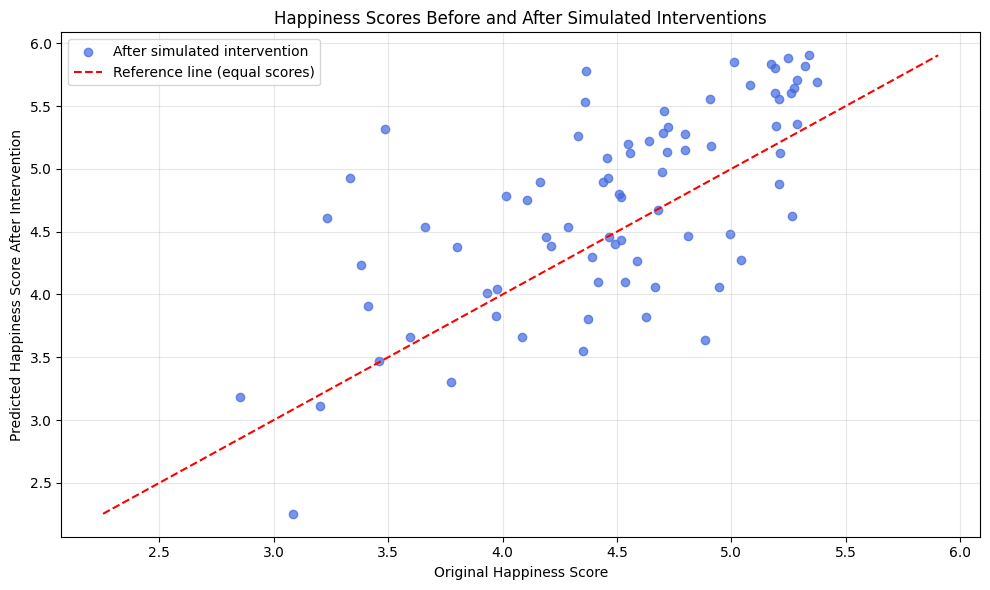

In [15]:

# ==========================================
# SCATTER PLOT: BEFORE AND AFTER INTERVENTION
# ==========================================

plt.figure(figsize=(10, 6))

plt.scatter(
    intervention_results["Original Happiness Score"],
    intervention_results["Predicted Score After Intervention"],
    alpha=0.7,
    color="royalblue",
    label="After simulated intervention"
)

# Add reference line representing no change
min_value = min(
    intervention_results["Original Happiness Score"].min(),
    intervention_results["Predicted Score After Intervention"].min()
)

max_value = max(
    intervention_results["Original Happiness Score"].max(),
    intervention_results["Predicted Score After Intervention"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red",
    label="Reference line (equal scores)"
)

# Labels and title
plt.xlabel("Original Happiness Score")
plt.ylabel("Predicted Happiness Score After Intervention")

plt.title(
    "Happiness Scores Before and After Simulated Interventions"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:

# ==========================================
# INTERVENTION SUMMARY
# ==========================================

total_countries = len(intervention_results)

improved_countries = (
    intervention_results["Predicted Score Change"] > 0
).sum()

unchanged_countries = (
    intervention_results["Predicted Score Change"] == 0
).sum()

decreased_countries = (
    intervention_results["Predicted Score Change"] < 0
).sum()

average_change = (
    intervention_results["Predicted Score Change"].mean()
)

display(Markdown("### Intervention Summary"))

print("Total countries analyzed:", total_countries)

print("Countries with increased predicted scores:",
      improved_countries)

print("Countries with unchanged predicted scores:",
      unchanged_countries)

print("Countries with decreased predicted scores:",
      decreased_countries)

print("Average predicted score improvement:",
      round(average_change, 6))

# Calculate percentage of countries improved
if total_countries > 0:
    improvement_percentage = (
        improved_countries / total_countries
    ) * 100

    print(
        "Percentage of countries with improvement:",
        round(improvement_percentage, 2), "%"
    )

### Intervention Summary

Total countries analyzed: 78
Countries with increased predicted scores: 78
Countries with unchanged predicted scores: 0
Countries with decreased predicted scores: 0
Average predicted score improvement: 0.09184
Percentage of countries with improvement: 100.0 %


In [19]:

# ==========================================
# TOP 10 COUNTRIES BY PREDICTED IMPROVEMENT
# ==========================================

top_improvements = intervention_results.sort_values(
    by="Predicted Score Change",
    ascending=False
)

display(
    Markdown(
        "### Countries with the Greatest Predicted "
        "Happiness Score Improvements"
    )
)

display(top_improvements.head(10))


### Countries with the Greatest Predicted Happiness Score Improvements

,Original Happiness Score,Baseline Predicted Score,Predicted Score After Intervention,Predicted Score Change
96,5.011,5.716369,5.852694,0.136325
80,5.323,5.684708,5.816700,0.131992
107,4.707,5.330132,5.460719,0.130587
82,5.285,5.574490,5.703706,0.129216
86,5.247,5.750214,5.879298,0.129084
93,5.175,5.707473,5.835724,0.128251
78,5.373,5.566638,5.693352,0.126714
85,5.261,5.478944,5.605654,0.126710
81,5.287,5.231666,5.356658,0.124992
132,4.332,5.138676,5.263378,0.124703
